# Conformal prediction for regression

### Basic libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Environment configuration for Kaggle

In [ ]:
import os
import json
from google.colab import userdata

os.environ['KAGGLE_USERNAME'] = 'gildas_kaggle_api'
os.environ['KAGGLE_KEY'] = userdata.get('API_KAGGLE_TOKEN')

In [ ]:
try:
  import kaggle
except:
  ! pip install kaggle

import kaggle
kaggle.api.authenticate()

### Downloading dataset

In [ ]:
!kaggle datasets download -d anthonypino/melbourne-housing-market

Dataset URL: https://www.kaggle.com/datasets/anthonypino/melbourne-housing-market
License(s): CC-BY-NC-SA-4.0
100% 2.28M/2.28M [00:00<00:00, 142MB/s]



### Unzip the dataset

In [ ]:
import zipfile
with zipfile.ZipFile('melbourne-housing-market.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')
print('File Unzipped!')

File Unzipped!


### Loading dataset

In [ ]:
data = pd.read_csv('/content/Melbourne_housing_FULL.csv')
data.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,68 Studley St,2,h,NaN,SS,Jellis,3/09/2016,2.5,3067.0,...,1.0,1.0,126.0,NaN,NaN,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019.0
1,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra City Council,-37.7996,144.9984,Northern Metropolitan,4019.0
2,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra City Council,-37.8079,144.9934,Northern Metropolitan,4019.0
3,Abbotsford,18/659 Victoria St,3,u,NaN,VB,Rounds,4/02/2016,2.5,3067.0,...,2.0,1.0,0.0,NaN,NaN,Yarra City Council,-37.8114,145.0116,Northern Metropolitan,4019.0
4,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra City Council,-37.8093,144.9944,Northern Metropolitan,4019.0


In [ ]:
data.tail()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
34852,Yarraville,13 Burns St,4,h,1480000.0,PI,Jas,24/02/2018,6.3,3013.0,...,1.0,3.0,593.0,NaN,NaN,Maribyrnong City Council,-37.81053,144.88467,Western Metropolitan,6543.0
34853,Yarraville,29A Murray St,2,h,888000.0,SP,Sweeney,24/02/2018,6.3,3013.0,...,2.0,1.0,98.0,104.0,2018.0,Maribyrnong City Council,-37.81551,144.88826,Western Metropolitan,6543.0
34854,Yarraville,147A Severn St,2,t,705000.0,S,Jas,24/02/2018,6.3,3013.0,...,1.0,2.0,220.0,120.0,2000.0,Maribyrnong City Council,-37.82286,144.87856,Western Metropolitan,6543.0
34855,Yarraville,12/37 Stephen St,3,h,1140000.0,SP,hockingstuart,24/02/2018,6.3,3013.0,...,NaN,NaN,NaN,NaN,NaN,Maribyrnong City Council,NaN,NaN,Western Metropolitan,6543.0
34856,Yarraville,3 Tarrengower St,2,h,1020000.0,PI,RW,24/02/2018,6.3,3013.0,...,1.0,0.0,250.0,103.0,1930.0,Maribyrnong City Council,-37.81810,144.89351,Western Metropolitan,6543.0


In [ ]:
data.shape

(34857, 21)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34857 entries, 0 to 34856
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         34857 non-null  object 
 1   Address        34857 non-null  object 
 2   Rooms          34857 non-null  int64  
 3   Type           34857 non-null  object 
 4   Price          27247 non-null  float64
 5   Method         34857 non-null  object 
 6   SellerG        34857 non-null  object 
 7   Date           34857 non-null  object 
 8   Distance       34856 non-null  float64
 9   Postcode       34856 non-null  float64
 10  Bedroom2       26640 non-null  float64
 11  Bathroom       26631 non-null  float64
 12  Car            26129 non-null  float64
 13  Landsize       23047 non-null  float64
 14  BuildingArea   13742 non-null  float64
 15  YearBuilt      15551 non-null  float64
 16  CouncilArea    34854 non-null  object 
 17  Lattitude      26881 non-null  float64
 18  Longti

## Step 1 : Preprocessing

## 1.1- Dealing with missing values and duplicated values

In [ ]:
data.isna().sum()

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,7610
Method,0
SellerG,0
Date,0
Distance,1
Postcode,1


In [ ]:
data.duplicated().sum()

np.int64(1)

Price is the target variable in our study, so we will drop every row where it has a missing value. That means removing 7,610 rows out of 34,857 (about 22%). The dataset remains representative for the purposes of our study. Imputing the target with a summary statistic (mean, median, etc.) would be inappropriate, as it would introduce artificial values into the variable we are trying to predict. We will also remove the duplicated row.

In [ ]:
data = data.dropna(subset=['Price'])
data = data.drop_duplicates()
data = data.reset_index(drop=True)
data.shape

(27247, 21)

In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data.isna().sum()

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Distance,1
Postcode,1


Here, we will look for a better strategy to impute the missing values in the other columns. We will not blindly drop rows, so as to preserve as much information as possible. However, for columns such as Distance, Postcode, CouncilArea, Regionname and Propertycount, we will simply drop the rows with missing values, since there are very few of them (3 at most).

In [ ]:
data = data.dropna(subset=['Distance'])
data = data.dropna(subset=['Postcode'])
data = data.dropna(subset=['CouncilArea'])
data = data.dropna(subset=['Regionname'])
data = data.dropna(subset=['Propertycount'])
data = data.reset_index(drop=True)
data.shape

(27244, 21)

In [ ]:
data.isna().sum()

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Distance,0
Postcode,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27244 entries, 0 to 27243
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         27244 non-null  object 
 1   Address        27244 non-null  object 
 2   Rooms          27244 non-null  int64  
 3   Type           27244 non-null  object 
 4   Price          27244 non-null  float64
 5   Method         27244 non-null  object 
 6   SellerG        27244 non-null  object 
 7   Date           27244 non-null  object 
 8   Distance       27244 non-null  float64
 9   Postcode       27244 non-null  float64
 10  Bedroom2       20806 non-null  float64
 11  Bathroom       20800 non-null  float64
 12  Car            20423 non-null  float64
 13  Landsize       17982 non-null  float64
 14  BuildingArea   10656 non-null  float64
 15  YearBuilt      12084 non-null  float64
 16  CouncilArea    27244 non-null  object 
 17  Lattitude      20993 non-null  float64
 18  Longti

### Decriptive statistics

In [ ]:
data.describe()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,27244.000000,2.724400e+04,27244.000000,27244.000000,20806.000000,20800.000000,20423.000000,17982.000000,10656.000000,12084.000000,20993.000000,20993.000000,27244.000000
mean,2.992365,1.050210e+06,11.280634,3113.799479,3.046237,1.591683,1.715370,593.488933,156.834586,1966.609153,-37.806963,144.996711,7566.781089
std,0.954810,6.414923e+05,6.787580,111.141993,0.955122,0.700880,0.994216,3757.266429,449.222791,36.762373,0.091619,0.120680,4492.382418
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.190430,144.423790,83.000000
25%,2.000000,6.350000e+05,6.400000,3046.000000,2.000000,1.000000,1.000000,219.000000,100.000000,1950.000000,-37.860900,144.925300,4294.000000
50%,3.000000,8.700000e+05,10.500000,3088.000000,3.000000,1.000000,2.000000,512.000000,133.000000,1970.000000,-37.800460,145.003200,6567.000000
75%,4.000000,1.295000e+06,14.000000,3153.000000,4.000000,2.000000,2.000000,664.000000,182.000000,2000.000000,-37.748970,145.068770,10412.000000
max,16.000000,1.120000e+07,48.100000,3978.000000,20.000000,9.000000,18.000000,433014.000000,44515.000000,2019.000000,-37.397800,145.526350,21650.000000


In [ ]:
data.describe(include='object')

,Suburb,Address,Type,Method,SellerG,Date,CouncilArea,Regionname
count,27244,27244,27244,27244,27244,27244,27244,27244
unique,344,26748,3,5,349,78,33,8
top,Reservoir,5 Charles St,h,S,Nelson,28/10/2017,Boroondara City Council,Southern Metropolitan
freq,727,4,18470,17514,2735,879,2520,8524


### Checking wheter missing values are random or systematic in those columns by using missingno approach

In [ ]:
cols = ["Bedroom2", "Bathroom", "Car", "Landsize",
        "BuildingArea", "YearBuilt", "Lattitude", "Longtitude"]

In [ ]:
!pip install missingno
import missingno as msno

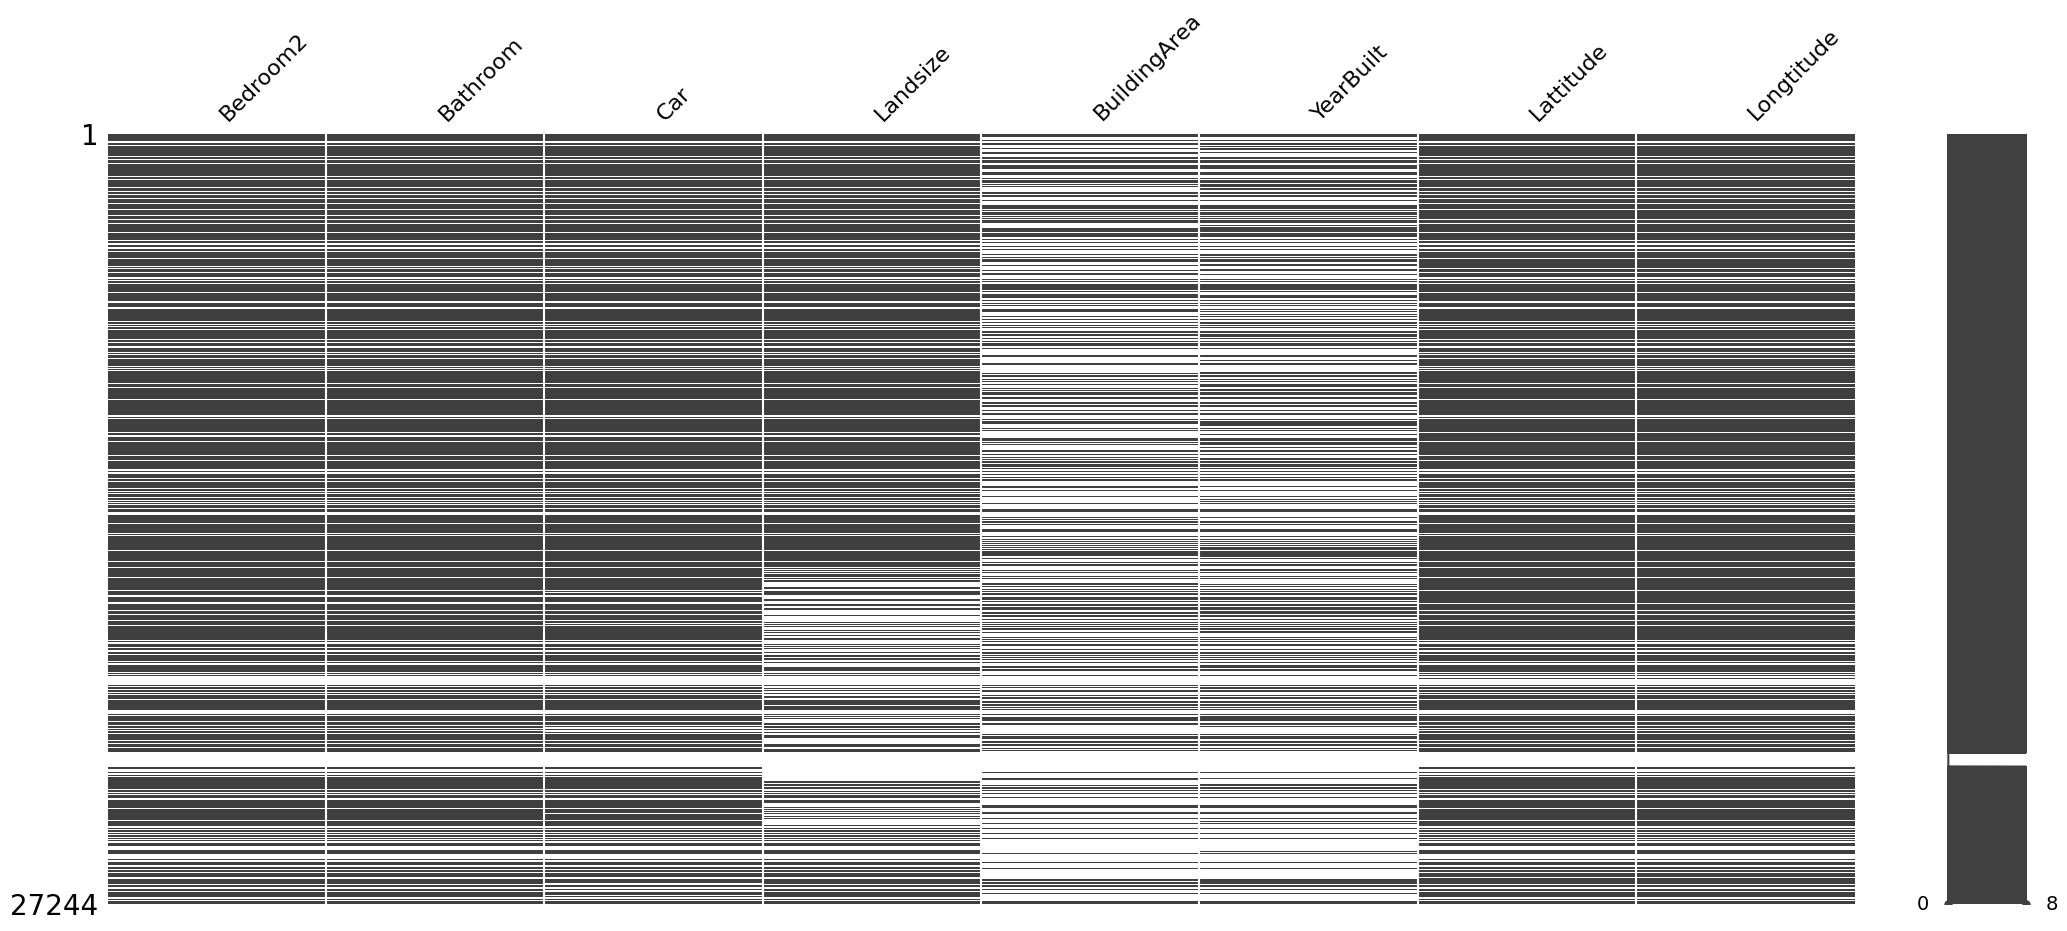

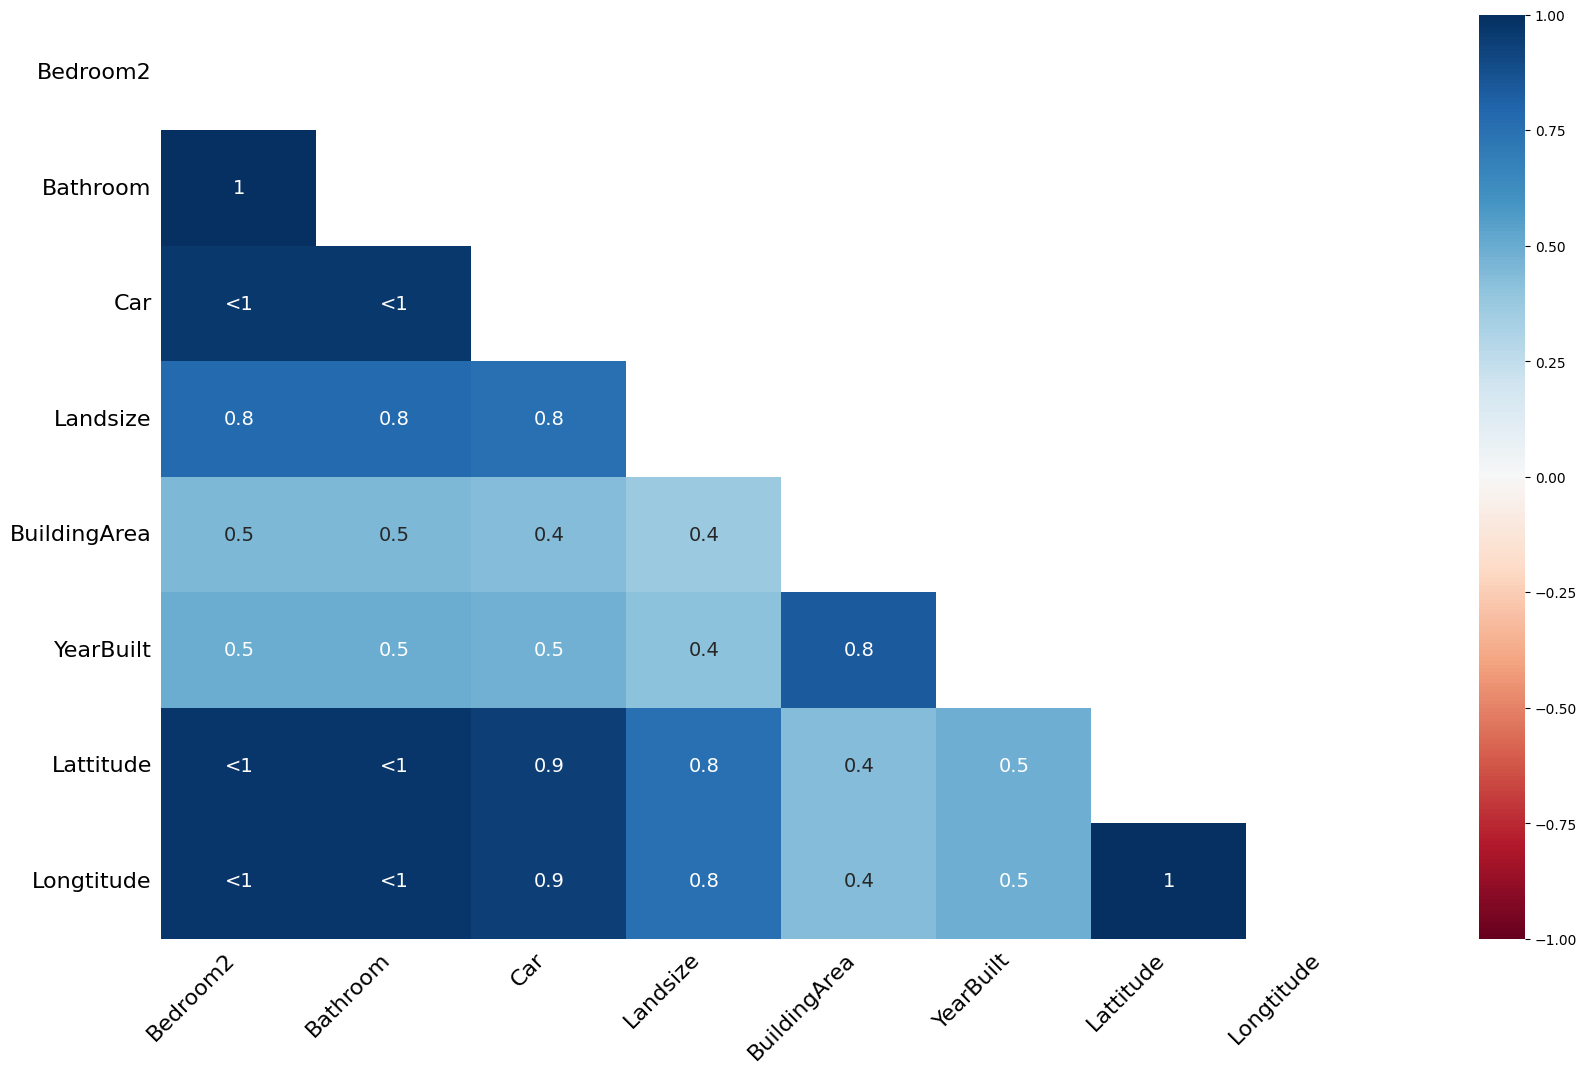

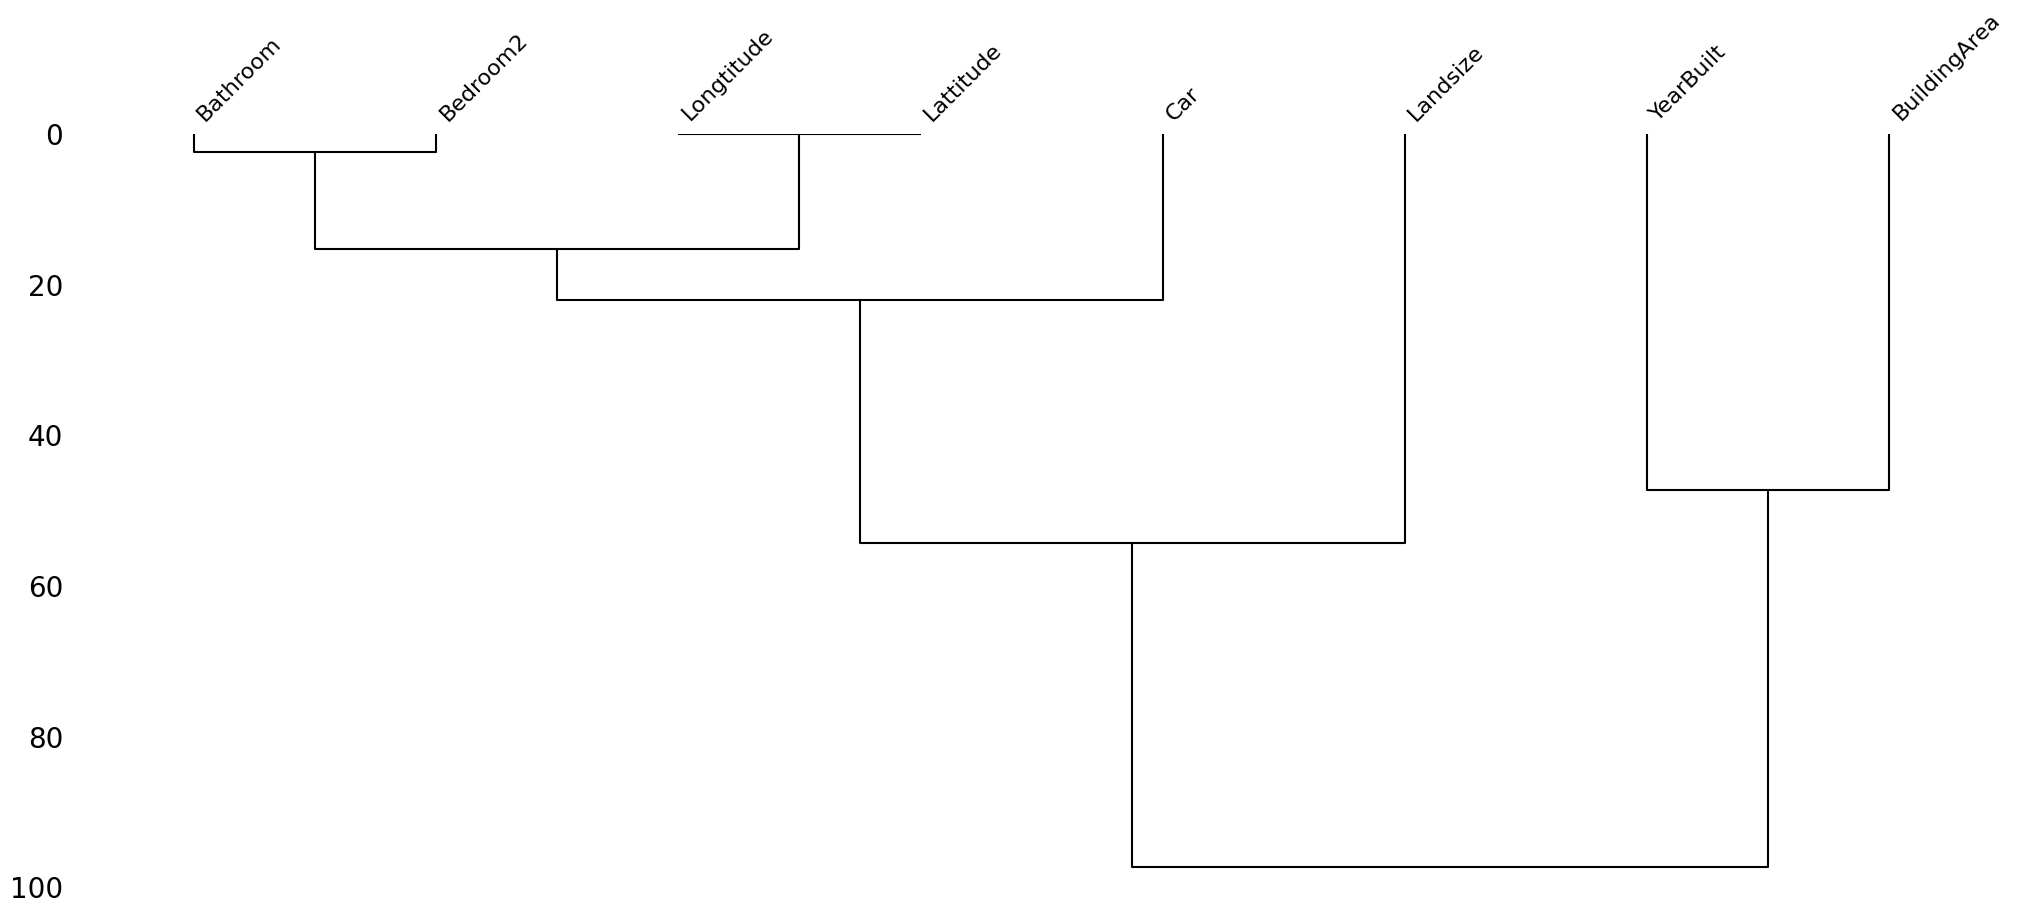

In [ ]:
msno.matrix(data[cols]); plt.show()
msno.heatmap(data[cols]); plt.show()
msno.dendrogram(data[cols]); plt.show()

Based on the Missingno results, we can draw the following conclusions:

* Bathroom and Bedroom2 are missing together, and their missingness patterns are similar

* Longitude and Latitude are missing together, and their missingness patterns are similar

* YearBuilt and BuildingArea are missing together, and their missingness patterns are similar

* Car and Landsize have a very strong correlation in terms of missing values and are related to the pairs (Bathroom, Bedroom2) & (Longitude, Latitude)

Proportion of rows where both pairs are simultaneously missing

In [ ]:
pairs = [("Bathroom", "Bedroom2"), ("Longtitude", "Lattitude"),
         ("YearBuilt", "BuildingArea")]


for a, b in pairs:
  print(a, b, ":", (data[a].isna() & data[b].isna()).mean().round(3))

Bathroom Bedroom2 : 0.236
Longtitude Lattitude : 0.229
YearBuilt BuildingArea : 0.542


In [ ]:
print(data[cols].corr().round(2))

              Bedroom2  Bathroom   Car  Landsize  BuildingArea  YearBuilt  \
Bedroom2          1.00      0.61  0.40      0.03          0.14       0.01   
Bathroom          0.61      1.00  0.31      0.04          0.13       0.19   
Car               0.40      0.31  1.00      0.03          0.09       0.13   
Landsize          0.03      0.04  0.03      1.00          0.38       0.04   
BuildingArea      0.14      0.13  0.09      0.38          1.00       0.07   
YearBuilt         0.01      0.19  0.13      0.04          0.07       1.00   
Lattitude         0.02     -0.05  0.00      0.02          0.03       0.10   
Longtitude        0.09      0.10  0.04     -0.00         -0.01      -0.02   

              Lattitude  Longtitude  
Bedroom2           0.02        0.09  
Bathroom          -0.05        0.10  
Car                0.00        0.04  
Landsize           0.02       -0.00  
BuildingArea       0.03       -0.01  
YearBuilt          0.10       -0.02  
Lattitude          1.00       -0.35  
Lo

In [ ]:
data.columns[data.notna().all()].tolist()

['Suburb',
 'Address',
 'Rooms',
 'Type',
 'Price',
 'Method',
 'SellerG',
 'Date',
 'Distance',
 'Postcode',
 'CouncilArea',
 'Regionname',
 'Propertycount']

### Imputation of Latitude & Longitude
 We will use median metric based on area by using Suburb, Postcode, CouncilArea and Regionname

In [ ]:
df = data.copy()

In [ ]:
for c in ["Lattitude", "Longtitude"]:
    for g in ["Suburb", "Postcode", "CouncilArea", "Regionname"]:
        df[c] = df[c].fillna(df.groupby(g)[c].transform("median"))

print(df[["Lattitude", "Longtitude"]].isna().sum())

Lattitude     0
Longtitude    0
dtype: int64


#### Auxiliary variables for imputing the other 6 variables

In [ ]:
df["Year"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce").dt.year
dummies = pd.get_dummies(df[["Type", "Regionname"]], dtype=float)

support = pd.concat(
    [df[["Rooms", "Price", "Distance", "Postcode", "Propertycount",
         "Year", "Lattitude", "Longtitude"]], dummies], axis=1)

#### Imputation

In [ ]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import ExtraTreesRegressor

In [ ]:
targets = ["Bedroom2", "Bathroom", "Car", "Landsize", "BuildingArea", "YearBuilt"]
X = pd.concat([df[targets], support], axis=1)

imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=50, n_jobs=-1, random_state=0),
    max_iter= 100,
    initial_strategy="median",
    imputation_order="ascending",
    random_state=0,
)
X_imp = pd.DataFrame(imputer.fit_transform(X), columns=X.columns, index=X.index)
df[targets] = X_imp[targets]

#### Post-treatment

In [ ]:
for c in ["Bedroom2", "Bathroom", "Car", "YearBuilt"]:
    df[c] = df[c].round().astype(int)
for c in ["Bedroom2", "Bathroom", "Car", "Landsize", "BuildingArea"]:
    df[c] = df[c].clip(lower=0)
df["YearBuilt"] = df["YearBuilt"].clip(data["YearBuilt"].min(), data["YearBuilt"].max())

data_imputed = df.drop(columns=["Year"])

In [ ]:
data_imputed.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1,1,202.0,101.020,1917,Yarra City Council,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1,0,156.0,79.000,1900,Yarra City Council,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2,0,134.0,150.000,1900,Yarra City Council,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2,1,94.0,114.396,1995,Yarra City Council,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1,2,120.0,142.000,2014,Yarra City Council,-37.8072,144.9941,Northern Metropolitan,4019.0


In [ ]:
data_imputed.tail()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
27239,Yarraville,13 Burns St,4,h,1480000.0,PI,Jas,24/02/2018,6.3,3013.0,...,1,3,593.00,158.58,1929,Maribyrnong City Council,-37.81053,144.88467,Western Metropolitan,6543.0
27240,Yarraville,29A Murray St,2,h,888000.0,SP,Sweeney,24/02/2018,6.3,3013.0,...,2,1,98.00,104.00,2018,Maribyrnong City Council,-37.81551,144.88826,Western Metropolitan,6543.0
27241,Yarraville,147A Severn St,2,t,705000.0,S,Jas,24/02/2018,6.3,3013.0,...,1,2,220.00,120.00,2000,Maribyrnong City Council,-37.82286,144.87856,Western Metropolitan,6543.0
27242,Yarraville,12/37 Stephen St,3,h,1140000.0,SP,hockingstuart,24/02/2018,6.3,3013.0,...,1,1,530.14,116.38,1929,Maribyrnong City Council,-37.81720,144.88580,Western Metropolitan,6543.0
27243,Yarraville,3 Tarrengower St,2,h,1020000.0,PI,RW,24/02/2018,6.3,3013.0,...,1,0,250.00,103.00,1930,Maribyrnong City Council,-37.81810,144.89351,Western Metropolitan,6543.0


In [ ]:
data_imputed.shape

(27244, 21)

In [ ]:
data_imputed.duplicated().sum()

np.int64(0)

In [ ]:
data_imputed.isna().sum()

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Distance,0
Postcode,0


### 1.2- Dealing with outliers

Let's identify outliers in main numerical columns

In [ ]:
cols_out = ['Rooms', 'Distance', 'Bedroom2',
            'Landsize', 'BuildingArea']
count_cols = ['Rooms', 'Bedroom2']

for col in cols_out:
    Q1, Q3 = data_imputed[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    print(col, ":", ((data_imputed[col] < lo) | (data_imputed[col] > hi)).sum())



Rooms : 23
Distance : 1188
Bedroom2 : 25
Landsize : 934
BuildingArea : 1245


Let's deal with those outliers by making sure they are in IQR

In [ ]:
for col in cols_out:
    Q1, Q3 = data_imputed[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    data_imputed[col] = data_imputed[col].clip(lower=Q1 - 1.5 * IQR, upper=Q3 + 1.5 * IQR)

data_imputed[count_cols] = data_imputed[count_cols].round()

Let's check wheter there are still outliers

In [ ]:
for col in cols_out:
    Q1, Q3 = data_imputed[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    print(col, ":", ((data_imputed[col] < lo) | (data_imputed[col] > hi)).sum())

Rooms : 0
Distance : 0
Bedroom2 : 0
Landsize : 0
BuildingArea : 0


The scaling of variables will be done in step 2

## Step 2 : Features extraction

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

cat_cols = ['Type', 'Regionname']
num_cols = ['Rooms', 'Distance', 'Bedroom2', 'Bathroom', 'Car', 'Landsize',
            'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Propertycount']


### Data Split

In [ ]:
data = data_imputed.copy()

In [ ]:
X = data[num_cols + cat_cols]
y = data['Price']
y_log = np.log(y)

X = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_log, test_size=0.2, random_state=42)



### Scaling

In [ ]:
scaler = StandardScaler()

X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

## Step 3 : Modeling

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

### Evaluation function

In [ ]:
def evaluate_model(model, X_test, y_test):

    pred = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    return rmse, mae, r2

### Linear Regression

In [ ]:
model1 = LinearRegression()
model1.fit(X_train_s, y_train)
y_pred = model1.predict(X_test_s)

In [ ]:
rmse, mae, r2 = evaluate_model(model1, X_test_s, y_test)
print("RMSE:", rmse)
print("MAE:", mae)
print("R2:", r2)

RMSE: 0.25321898505596424
MAE: 0.1924902314485652
R2: 0.7644808813818683


### RandomForest

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
model2 = RandomForestRegressor(random_state=42)

model2_params = {
    "n_estimators": [100, 400],
    "max_depth": [5, 50],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [2, 4]
}

model2_search = RandomizedSearchCV(
    model2,
    model2_params,
    n_iter=5,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42
)

In [ ]:
model2_search.fit(X_train_s, y_train)

model2_best = model2_search.best_estimator_

In [ ]:
rmse_2, mae_2, r2_2= evaluate_model(
    model2_best,
    X_test_s,
    y_test
)

In [ ]:
print("RMSE:", rmse_2)
print("MAE:", mae_2)
print("R2:", r2_2)

RMSE: 0.1656810684304666
MAE: 0.11940532728138468
R2: 0.8991724038962594


## Conformal Prediction

In [ ]:
! pip install mapie

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.3/573.3 kB 10.6 MB/s  0:00:00


In [ ]:
from mapie.regression import CrossConformalRegressor
from mapie.metrics.regression import regression_coverage_score, regression_mean_width_score
from sklearn.model_selection import LeaveOneOut, KFold
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

### Models and predictive performance

In [ ]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=50, min_samples_leaf=2,
                                           random_state=42, n_jobs=-1),
}

rows = []
for name, m in models.items():
    m = clone(m).fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({"Model": name,
                 "R2": r2_score(y_test, p),
                 "MAE": mean_absolute_error(y_test, p),
                 "RMSE": np.sqrt(mean_squared_error(y_test, p))})
pd.DataFrame(rows).set_index("Model").round(3)

,R2,MAE,RMSE
Model,,,
Linear Regression,0.764,0.192,0.253
Random Forest,0.901,0.118,0.164


### Sample of training

In [ ]:
N_SUB = 2000
rng = np.random.RandomState(42)
idx = rng.choice(len(X_train), N_SUB, replace=False)
X_sub, y_sub = X_train.iloc[idx], y_train.iloc[idx]

### Jackknife and CV with MAPIE (4 combinations)

In [ ]:
alpha = 0.1
cp_methods = {
    "Jackknife": LeaveOneOut(),
    "CV (K=5)": KFold(n_splits=5, shuffle=True, random_state=42),
}

res, store = [], {}
for name, model in models.items():
    for cp_name, cv in cp_methods.items():
        mapie = CrossConformalRegressor(estimator=model,
                                        confidence_level=1 - alpha,
                                        method="base",
                                        cv=cv)
        mapie.fit_conformalize(X_sub, y_sub)
        y_pred, y_pis = mapie.predict_interval(X_test)
        lo, hi = y_pis[:, 0, 0], y_pis[:, 1, 0]
        store[(name, cp_name)] = (y_pred, lo, hi)
        res.append({
            "Model": name, "CP": cp_name,
            "Coverage": regression_coverage_score(y_test, y_pis)[0],
            "Mean width (log)": regression_mean_width_score(y_pis)[0],
            "Median ratio hi/lo": np.median(np.exp(hi - lo)),
        })

results = pd.DataFrame(res).round(3)
results["Target"] = 1 - alpha
results

,Model,CP,Coverage,Mean width (log),Median ratio hi/lo,Target
0,Linear Regression,Jackknife,0.902,0.819,2.269,0.9
1,Linear Regression,CV (K=5),0.903,0.825,2.281,0.9
2,Random Forest,Jackknife,0.914,0.664,1.943,0.9
3,Random Forest,CV (K=5),0.919,0.679,1.972,0.9


### Empirical vs. Nominal Coverage

In [ ]:
levels = [0.7, 0.8, 0.9, 0.95]
rows = []
for name, model in models.items():
    for cp_name, cv in cp_methods.items():
        mapie = CrossConformalRegressor(estimator=model, confidence_level=levels,
                                        method="base", cv=cv)
        mapie.fit_conformalize(X_sub, y_sub)
        _, y_pis = mapie.predict_interval(X_test)
        cov = regression_coverage_score(y_test, y_pis)
        wid = regression_mean_width_score(y_pis)
        for l, c, w in zip(levels, cov, wid):
            rows.append({"Model": name, "CP": cp_name, "Nominal": l, "Coverage": c, "Width": w})
cov_df = pd.DataFrame(rows)


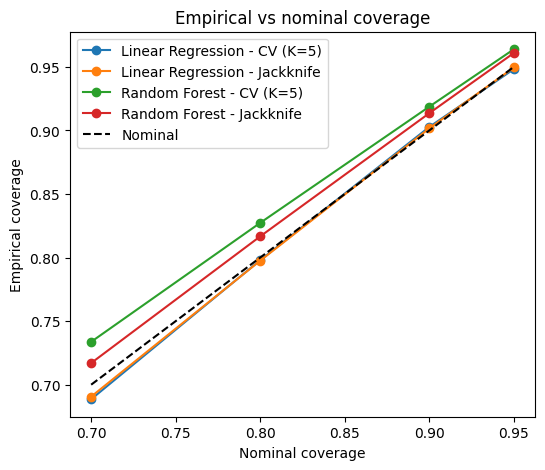

,Model,CP,Nominal,Coverage,Width
0,Linear Regression,Jackknife,0.70,0.691,0.482
1,Linear Regression,Jackknife,0.80,0.798,0.614
2,Linear Regression,Jackknife,0.90,0.902,0.819
3,Linear Regression,Jackknife,0.95,0.950,1.022
4,Linear Regression,CV (K=5),0.70,0.689,0.479
5,Linear Regression,CV (K=5),0.80,0.798,0.615
6,Linear Regression,CV (K=5),0.90,0.903,0.825
7,Linear Regression,CV (K=5),0.95,0.948,1.015
8,Random Forest,Jackknife,0.70,0.717,0.366
9,Random Forest,Jackknife,0.80,0.817,0.474


In [ ]:
plt.figure(figsize=(6, 5))
for (n, c), g in cov_df.groupby(["Model", "CP"]):
    plt.plot(g["Nominal"], g["Coverage"], marker="o", label=f"{n} - {c}")
plt.plot([0.7, 0.95], [0.7, 0.95], "k--", label="Nominal")
plt.xlabel("Nominal coverage"); plt.ylabel("Empirical coverage"); plt.legend()
plt.title("Empirical vs nominal coverage"); plt.show()
cov_df.round(3)

### Interval Width and Its Relationship to Prediction Error

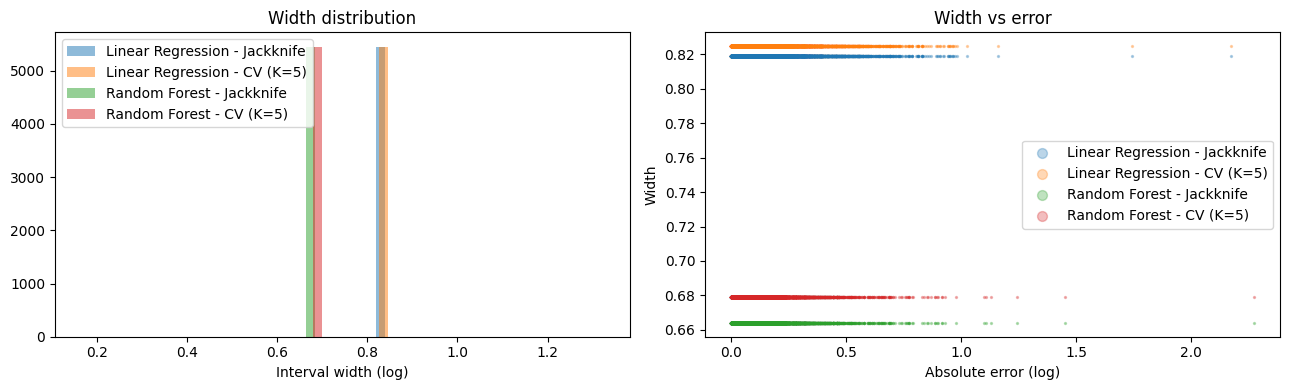

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (n, c), (pred, lo, hi) in store.items():
    ax[0].hist(hi - lo, bins=50, alpha=0.5, label=f"{n} - {c}")
    ax[1].scatter(np.abs(np.asarray(y_test) - pred), hi - lo, s=2, alpha=0.3, label=f"{n} - {c}")
ax[0].set_xlabel("Interval width (log)"); ax[0].legend(); ax[0].set_title("Width distribution")
ax[1].set_xlabel("Absolute error (log)"); ax[1].set_ylabel("Width")
ax[1].legend(markerscale=5); ax[1].set_title("Width vs error")
plt.tight_layout(); plt.show()

### Conditional Coverage by Property Type

In [ ]:
info = data.loc[X_test.index, "Type"].values
rows = []
for (n, c), (pred, lo, hi) in store.items():
    covd = (np.asarray(y_test) >= lo) & (np.asarray(y_test) <= hi)
    g = (pd.DataFrame({"Type": info, "cov": covd, "w": hi - lo})
           .groupby("Type").agg(coverage=("cov", "mean"), width=("w", "mean"), n=("cov", "size")))
    g["Model"], g["CP"] = n, c
    rows.append(g.reset_index())
pd.concat(rows).round(3)

,Type,coverage,width,n,Model,CP
0,h,0.918,0.819,3722,Linear Regression,Jackknife
1,t,0.942,0.819,555,Linear Regression,Jackknife
2,u,0.832,0.819,1172,Linear Regression,Jackknife
0,h,0.918,0.825,3722,Linear Regression,CV (K=5)
1,t,0.944,0.825,555,Linear Regression,CV (K=5)
2,u,0.834,0.825,1172,Linear Regression,CV (K=5)
0,h,0.923,0.664,3722,Random Forest,Jackknife
1,t,0.915,0.664,555,Random Forest,Jackknife
2,u,0.883,0.664,1172,Random Forest,Jackknife
0,h,0.929,0.679,3722,Random Forest,CV (K=5)


### Examples of Prediction Intervals in Dollars

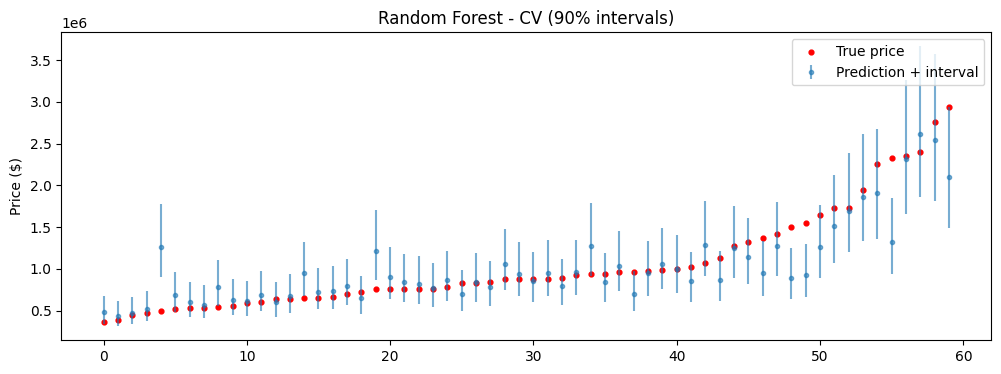

In [ ]:
pred, lo, hi = store[("Random Forest", "CV (K=5)")]
sel = np.random.RandomState(0).choice(len(y_test), 60, replace=False)
sel = sel[np.argsort(np.asarray(y_test)[sel])]
plt.figure(figsize=(12, 4))
plt.errorbar(range(60), np.exp(pred[sel]),
             yerr=[np.exp(pred[sel]) - np.exp(lo[sel]), np.exp(hi[sel]) - np.exp(pred[sel])],
             fmt="o", ms=3, alpha=0.6, label="Prediction + interval")
plt.scatter(range(60), np.exp(np.asarray(y_test)[sel]), c="red", s=12, label="True price")
plt.ylabel("Price ($)"); plt.legend(); plt.title("Random Forest - CV (90% intervals)"); plt.show()